# Cancelamento de reservas de hotel: variáveis do modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Este notebook** parte da base definida no `01_exploratoria.ipynb` (reservas sem depósito, com a limpeza proposta) e decide quais variáveis entram no modelo e de que forma. O modelo e a avaliação ficam no `03_modelo.ipynb`.

Todas as decisões saem do **treino** (chegadas de 2015 e 2016). O teste (2017) só aparece quando a pergunta é se uma relação se mantém no tempo.

## Resumo

*(preenchido ao final da análise)*

- Variáveis que entram, e de que forma: __.
- Variáveis que saem, e por quê: __.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes_logistica import (CORES, aplicar_estilo, preparar_base,
                               taxa_por_nivel, grafico_taxa_por_nivel,
                               logito_por_faixa, grafico_logito, v_cramer)

aplicar_estilo()
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base do modelo

O escopo e a limpeza vêm do `01_exploratoria.ipynb`: só reservas sem depósito (seção 5.2) e as remoções propostas na seção 4. A função `preparar_base` aplica os dois e acrescenta o total de noites, o total de hóspedes e a marcação de linhas com gêmea idêntica.

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, passos = preparar_base(hotel)
display(passos)

treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Teste: ', len(teste), f"| cancelamento {teste['is_canceled'].mean():.1%}")

jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']

,reservas,saem neste passo
base inteira,119390,NaN
sem depósito (escopo),104641,14749.0
children preenchido,104637,4.0
com hóspede,104457,180.0
diária entre 0 e 1.000,104456,1.0


Treino: 67990 | cancelamento 26.6%
Teste:  36466 | cancelamento 31.8%


**Leitura.**

- **Ficam 104.456 reservas.** O escopo tira 14.749 com depósito. As remoções tiram mais 185: 4 sem `children`, 180 sem hóspede e a diária negativa. A diária de 5.400 já tinha saído com o escopo (é Non Refund).
- **Treino: 67.990 reservas, 26,6% de cancelamento. Teste: 36.466, 31,8%.**
- As remoções seguem a proposta do notebook 01, seção 4. Duas divergem dos notebooks do grupo (ver `comparacao_decisoes.md`). Como somam 5 reservas, nenhuma das duas escolhas muda os resultados.

## 2. Univariada

**Perguntas:** como cada candidata se distribui? Há variáveis quase constantes, caudas longas ou categorias pequenas demais para estimar? A distribuição muda entre treino e teste?

As distribuições são descritas no **treino**; o teste só entra na comparação do fim da seção.

### 2.1 Numéricas

In [3]:
numericas = ['lead_time', 'adr', 'noites', 'stays_in_weekend_nights', 'stays_in_week_nights',
             'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
             'days_in_waiting_list', 'total_of_special_requests']

def resumo_numerica(s):
    return pd.Series({'pct_zero': (s == 0).mean(), 'p25': s.quantile(.25), 'mediana': s.median(),
                      'p75': s.quantile(.75), 'p95': s.quantile(.95), 'p99': s.quantile(.99), 'max': s.max()})

treino[numericas].apply(resumo_numerica).T.round(3)

,pct_zero,p25,mediana,p75,p95,p99,max
lead_time,0.066,12.0,50.0,124.0,272.00,351.000,737.0
adr,0.021,66.0,90.0,120.0,184.45,239.652,508.0
noites,0.008,2.0,3.0,4.0,7.00,14.000,69.0
stays_in_weekend_nights,0.427,0.0,1.0,2.0,2.00,4.000,19.0
stays_in_week_nights,0.070,1.0,2.0,3.0,5.00,10.000,50.0
adults,0.002,2.0,2.0,2.0,3.00,3.000,55.0
children,0.926,0.0,0.0,0.0,1.00,2.000,10.0
babies,0.990,0.0,0.0,0.0,0.00,0.000,10.0
previous_cancellations,0.962,0.0,0.0,0.0,0.00,1.000,24.0
previous_bookings_not_canceled,0.968,0.0,0.0,0.0,0.00,3.000,58.0


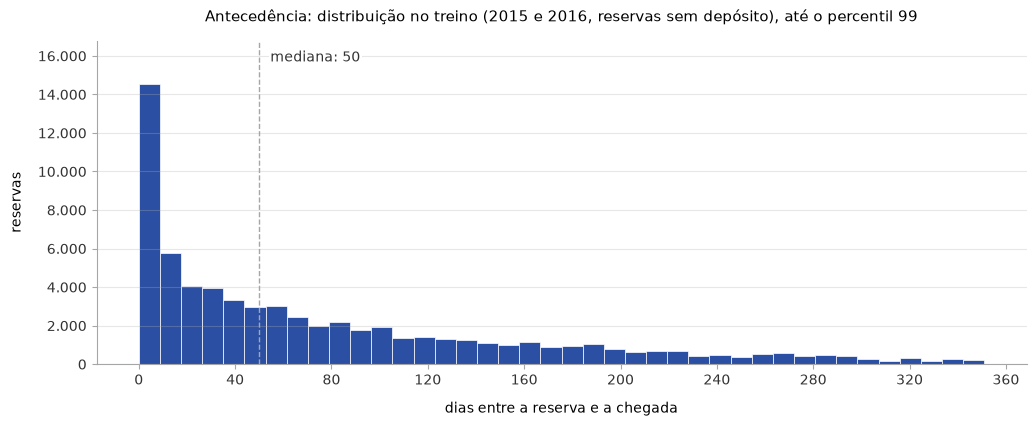

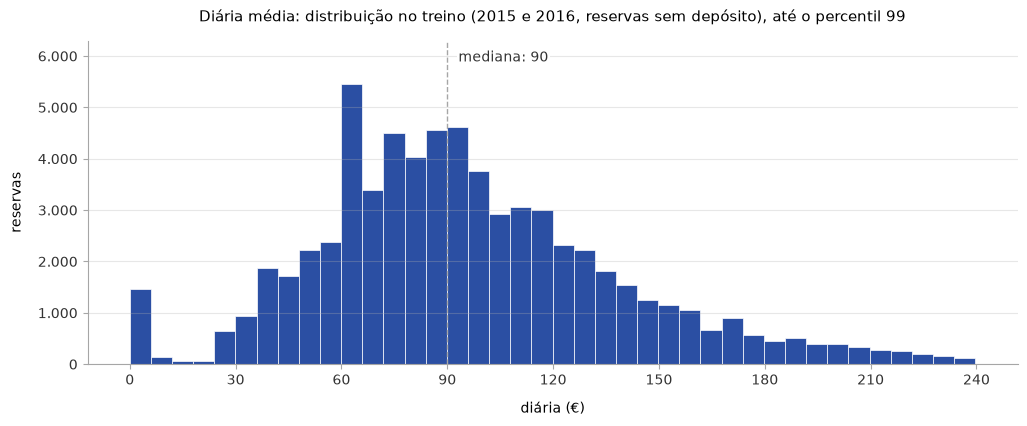

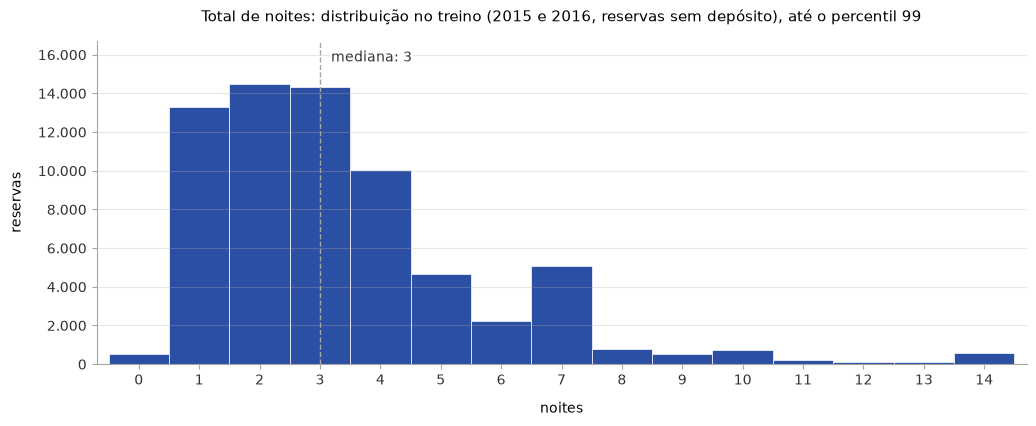

In [4]:
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

milhar = FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))   # 14.000, no padrão brasileiro

# uma figura por variável; a cauda acima do percentil 99 fica fora do gráfico (está na tabela acima)
for coluna, titulo, rotulo in [
        ('lead_time', 'Antecedência', 'dias entre a reserva e a chegada'),
        ('adr', 'Diária média', 'diária (€)'),
        ('noites', 'Total de noites', 'noites')]:
    s = treino[coluna]
    limite = s.quantile(0.99)
    bins = np.arange(0, limite + 2) - 0.5 if coluna == 'noites' else 40
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.hist(s[s <= limite], bins=bins, color=CORES['principal'], edgecolor='white', linewidth=0.5)
    ax.axvline(s.median(), color=CORES['referencia'], linestyle='--', linewidth=1)
    # rótulo ao lado do topo da linha da mediana, numa folga acima da barra mais alta
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.annotate(f'mediana: {s.median():.0f}', xy=(s.median(), 0.97), xycoords=ax.get_xaxis_transform(),
                xytext=(8, 0), textcoords='offset points',   # 8 pontos à direita da linha
                fontsize=10, color='#333333', ha='left', va='top',
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_title(f'{titulo}: distribuição no treino (2015 e 2016, reservas sem depósito), até o percentil 99')
    ax.set_xlabel(rotulo)
    ax.set_ylabel('reservas')
    if coluna == 'noites':
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.set_xlim(-0.7, limite + 0.7)
    else:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(milhar)
    plt.show()


**Leitura.**

- **`lead_time` tem cauda longa.** Mediana de 50 dias, mas o percentil 99 é 351 e o máximo, 737. 6,6% das reservas são para o próprio dia. Uma reta no logito dificilmente cobre de 0 a 737 dias: confirma a ideia das faixas, a conferir na bivariada.
- **`adr` concentra-se entre 66 e 120** (p25 e p75), com mediana de 90, percentil 99 de 240 e máximo de 508. 2,1% das reservas têm diária zero, que aparece como pico à esquerda no gráfico.
- **`noites`: metade das reservas fica de 2 a 4 noites** (p25 e p75), com mediana de 3 e percentil 99 de 14. O pico em 7 é a semana fechada. Faixas de 1, 2–3, 4–7 e mais de 7 noites acompanham esse desenho.
- **Cinco contagens são quase sempre zero:** `babies` (99,0%), `days_in_waiting_list` (97,7%), `previous_bookings_not_canceled` (96,8%), `previous_cancellations` (96,2%) e `children` (92,6%). Como número, o pouco que não é zero vira cauda (até 58 reservas anteriores mantidas). Se entrarem, entram como sim ou não. `babies` sozinho quase não varia; a bivariada (seção 3.1) mostra se dá para juntar com `children`.
- **`total_of_special_requests`:** 56,3% sem pedido. Candidata a "fez pedido × não fez".
- **`adults`:** o p25 e o p75 são 2, e o máximo é 55. Como número, a cauda pesa mais que o comum. Candidata a "sozinho × acompanhado".

### 2.2 Categóricas

In [5]:
categoricas = ['hotel', 'market_segment', 'distribution_channel', 'customer_type', 'meal',
               'reserved_room_type', 'is_repeated_guest']

frequencias = pd.concat({
    c: treino[c].value_counts().rename('reservas').to_frame().assign(pct=lambda t: t['reservas'] / t['reservas'].sum())
    for c in categoricas
})
frequencias.index.names = ['variavel', 'nivel']
frequencias['abaixo_de_1pct'] = frequencias['pct'] < 0.01
frequencias.round(4)

reservas     pct  abaixo_de_1pct
variavel             nivel                                            
hotel                City Hotel          42651  0.6273           False
                     Resort Hotel        25339  0.3727           False
market_segment       Online TA           33735  0.4962           False
                     Offline TA/TO       14666  0.2157           False
                     Direct               7942  0.1168           False
                     Groups               7424  0.1092           False
                     Corporate            3575  0.0526           False
                     Complementary         521  0.0077            True
                     Aviation              127  0.0019            True
distribution_channel TA/TO               54270  0.7982           False
                     Direct               9174  0.1349           False
                     Corporate            4440  0.0653           False
                     GDS                   105  0.0015            True
                     Undefined               1  0.0000            True
customer_type        Transient           46945  0.6905           False
                     Transient-Party     17831  0.2623           False
                     Contract             2866  0.0422           False
                     Group                 348  0.0051            True
meal                 BB                  53147  0.7817           False
                     HB                   8382  0.1233           False
                     SC                   5408  0.0795           False
                     Undefined             644  0.0095            True
                     FB                    409  0.0060            True
reserved_room_type   A                   48026  0.7064           False
                     D                   11427  0.1681           False
                     E                    3744  0.0551           False
                     F                    1794  0.0264           False
                     G                    1256  0.0185           False
                     B                     900  0.0132           False
                     C                     450  0.0066            True
                     H                     387  0.0057            True
                     L                       6  0.0001            True
is_repeated_guest    0                   65673  0.9659           False
                     1                    2317  0.0341           False

In [6]:
# meses: volume por mês de chegada no treino (2015 só tem julho a dezembro)
meses = ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December']
pd.crosstab(pd.Categorical(treino['arrival_date_month'], meses), treino['arrival_date_year'], margins=True)

arrival_date_year,2015,2016,All
row_0,,,
January,0,2050,2050
February,0,3382,3382
March,0,4229,4229
April,0,4481,4481
May,0,4745,4745
June,0,4316,4316
July,2544,4282,6826
August,3299,4792,8091
September,3905,4636,8541


**Leitura.**

- **Categorias abaixo de 1% do treino:**
  - `market_segment`: Complementary (0,8%) e Aviation (0,2%). Juntam em "Outros";
  - `customer_type`: Group (348 reservas, 0,5%). Precisa juntar com outra categoria; a bivariada mostra com qual ela se parece;
  - `meal`: Undefined (644, 0,95%) e FB (409, 0,6%). Undefined fica separado ou junta com SC (notebook 01, seção 4.3); FB pode juntar com HB em "com pensão";
  - `reserved_room_type`: C, H e L (L tem 6 reservas). A variável tende a sair: o código do quarto não significa nada para o público;
  - `distribution_channel`: GDS (0,15%) e uma reserva Undefined. A variável tende a sair por repetir o segmento.
- **Referências naturais (a categoria mais frequente):** City Hotel (62,7%), Online TA (49,6%), Transient (69,1%), BB (78,2%).
- **`is_repeated_guest`:** 3,4% de hóspedes que voltam. Pequeno, mas são 2.317 reservas: dá para estimar.
- **O treino não pesa os meses por igual.** 2015 só tem julho a dezembro, então esses meses aparecem em dois anos e janeiro a junho, só em 2016. O efeito de janeiro a junho é estimado com um ano só.

### 2.3 Treino × teste

In [7]:
# a distribuição das candidatas muda em 2017? (o teste só tem janeiro a agosto)
comparacao_num = pd.DataFrame({
    'mediana_treino': treino[['lead_time', 'adr', 'noites']].median(),
    'mediana_teste': teste[['lead_time', 'adr', 'noites']].median(),
})
display(comparacao_num)

# mesmos meses (janeiro a agosto) para tirar o efeito da época do ano na diária e na antecedência
treino_jan_ago = treino[treino['arrival_date_month'].isin(jan_a_ago) & (treino['arrival_date_year'] == 2016)]
display(pd.DataFrame({
    'mediana_2016_jan_ago': treino_jan_ago[['lead_time', 'adr', 'noites']].median(),
    'mediana_2017_jan_ago': teste[['lead_time', 'adr', 'noites']].median(),
}))

composicao = pd.concat({
    c: pd.DataFrame({'treino': treino[c].value_counts(normalize=True),
                     'teste': teste[c].value_counts(normalize=True)})
    for c in ['hotel', 'market_segment', 'customer_type']
}).fillna(0)
composicao['diferenca_pp'] = (composicao['teste'] - composicao['treino']) * 100
composicao.round(3)

,mediana_treino,mediana_teste
lead_time,50.0,73.0
adr,90.0,108.0
noites,3.0,3.0


,mediana_2016_jan_ago,mediana_2017_jan_ago
lead_time,54.0,73.0
adr,94.5,108.0
noites,3.0,3.0


treino  teste  diferenca_pp
hotel          City Hotel        0.627  0.648         2.041
               Resort Hotel      0.373  0.352        -2.041
market_segment Aviation          0.002  0.003         0.109
               Complementary     0.008  0.006        -0.199
               Corporate         0.053  0.038        -1.504
               Direct            0.117  0.127         0.972
               Groups            0.109  0.084        -2.517
               Offline TA/TO     0.216  0.124        -9.214
               Online TA         0.496  0.620        12.352
customer_type  Transient         0.690  0.812        12.130
               Transient-Party   0.262  0.164        -9.811
               Contract          0.042  0.018        -2.405
               Group             0.005  0.006         0.086

**Leitura.**

- **2017 reserva com mais antecedência e paga mais caro.** Nos mesmos meses (janeiro a agosto), a antecedência mediana sobe de 54 para 73 dias, e a diária mediana, de 94,5 para 108. O total de noites não muda (3).
- **O mix muda bastante:**
  - a agência online passa de 49,6% para 62,0% das reservas (+12,4 pontos), e a operadora tradicional cai 9,2 pontos;
  - o cliente avulso (Transient) passa de 69,0% para 81,2% (+12,1 pontos), e o avulso ligado a outra reserva (Transient-Party) cai 9,8 pontos.
- **O que isso muda:**
  - se a bivariada mostrar que a agência online e a antecedência longa cancelam mais, parte da alta de 2017 vem da composição. Essa parte o modelo capta, porque as variáveis estão nele; o resto aparece na calibração;
  - a diária sobe em 2017 também por preço. Se `adr` entrar como número, a mesma diária quer dizer coisas diferentes em cada ano. A conferir na bivariada se a relação entre a diária e o cancelamento é a mesma no treino e no teste.

## 3. Bivariada

**Pergunta:** como cada candidata se relaciona com o cancelamento, e em que forma ela entra no modelo?

Tudo no **treino** (2015 e 2016, no escopo). O teste só aparece quando a pergunta é se a relação se mantém em 2017.

### 3.1 Numéricas: número, faixas ou binária?

Na regressão logística, uma variável numérica tem efeito de reta no logito. O gráfico abaixo mostra o logito empírico de cada faixa contra o valor típico da faixa (a mediana): se os pontos caem numa reta, a variável entra como número; se não, vira faixas ou binária. Contínuas são cortadas em decis; contagens, por valor.

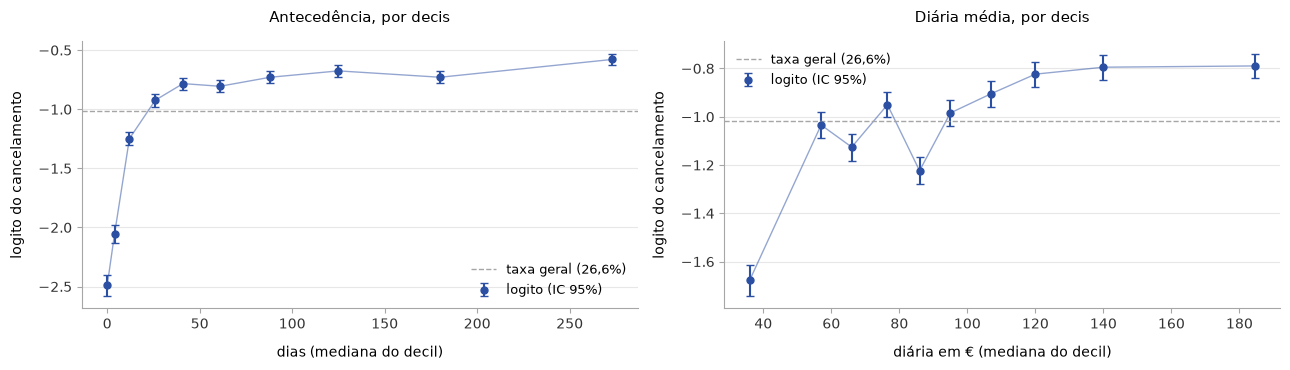

,n,taxa,logito,x
lead_time,,,,
"(-0.001, 1.0]",6907,0.076,-2.491,0.0
"(1.0, 7.0]",6857,0.114,-2.052,4.0
"(7.0, 18.0]",7086,0.223,-1.249,12.0
"(18.0, 33.0]",6512,0.284,-0.923,26.0
"(33.0, 50.0]",6670,0.314,-0.783,41.0
"(50.0, 73.0]",6797,0.309,-0.806,61.0
"(73.0, 104.0]",6874,0.325,-0.729,88.0
"(104.0, 150.0]",6784,0.337,-0.675,125.0
"(150.0, 215.0]",6753,0.325,-0.729,180.0


,n,taxa,logito,x
adr,,,,
"(-0.001, 47.0]",6822,0.157,-1.677,36.000
"(47.0, 62.0]",7096,0.262,-1.034,57.000
"(62.0, 72.0]",6680,0.245,-1.126,66.000
"(72.0, 80.75]",6940,0.279,-0.950,76.500
"(80.75, 90.0]",6776,0.227,-1.224,85.945
"(90.0, 100.0]",6724,0.272,-0.984,95.000
"(100.0, 113.0]",6557,0.288,-0.905,107.000
"(113.0, 129.0]",6807,0.305,-0.824,120.000
"(129.0, 156.6]",6811,0.311,-0.795,140.000


,n,taxa,ic_inf,ic_sup
faixa_adr,,,,
zero,1412,0.104,0.089,0.121
até 47,5410,0.171,0.162,0.182
acima de 47,61168,0.278,0.274,0.282


In [8]:
taxa_treino = treino['is_canceled'].mean()

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (coluna, titulo, rotulo) in zip(eixos, [('lead_time', 'Antecedência, por decis', 'dias (mediana do decil)'),
                                                ('adr', 'Diária média, por decis', 'diária em € (mediana do decil)')]):
    grafico_logito(logito_por_faixa(treino, coluna), titulo=titulo, rotulo_x=rotulo, taxa_geral=taxa_treino, ax=ax)
plt.tight_layout()
plt.show()

colunas = ['n', 'taxa', 'logito', 'x']
display(logito_por_faixa(treino, 'lead_time')[colunas].round(3))
display(logito_por_faixa(treino, 'adr')[colunas].round(3))

# o primeiro decil da diária inclui as diárias zero (notebook 01, seção 4.3)
taxa_por_nivel(treino.assign(faixa_adr=pd.cut(treino['adr'], [-1, 0, 47, np.inf], labels=['zero', 'até 47', 'acima de 47'])),
               'faixa_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

**Leitura.**

- **A antecedência não é linear no logito.** O cancelamento sobe rápido até um mês, de 7,6% (no mesmo dia ou no seguinte) para 28,4% (19 a 33 dias), e depois quase para: entre 30,9% e 35,9% de 34 a 737 dias. Uma reta não cobre os dois trechos. **Entra em faixas.**
- **A diária também não é linear.** O primeiro decil (até 47) cancela 15,7%, puxado pelas diárias zero (10,4%). Entre 47 e 100, a taxa oscila de 22,7% a 27,9%, sem escada; acima de 113, fica perto de 31%. **Vira faixas.** Os cortes ficam para depois de controlar hotel e temporada: a diária muda com os dois, e parte desse desenho pode vir deles.

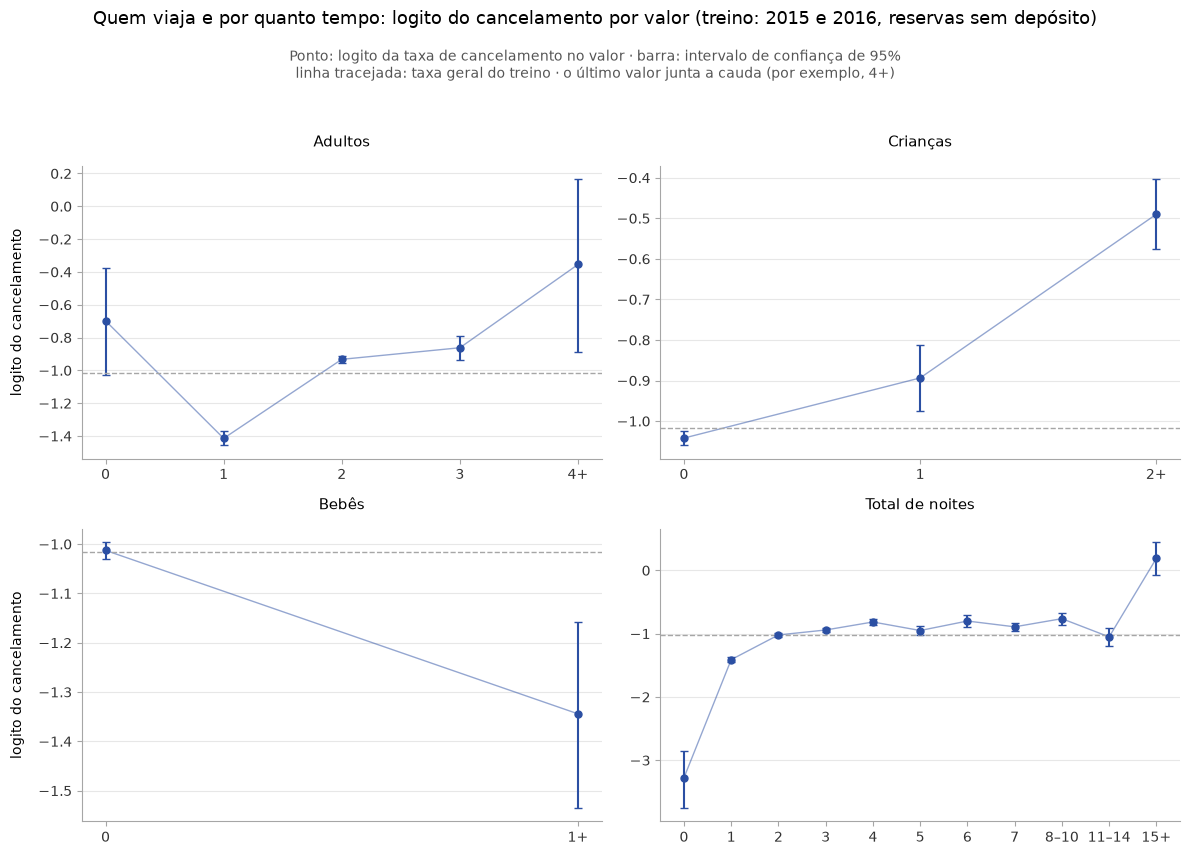

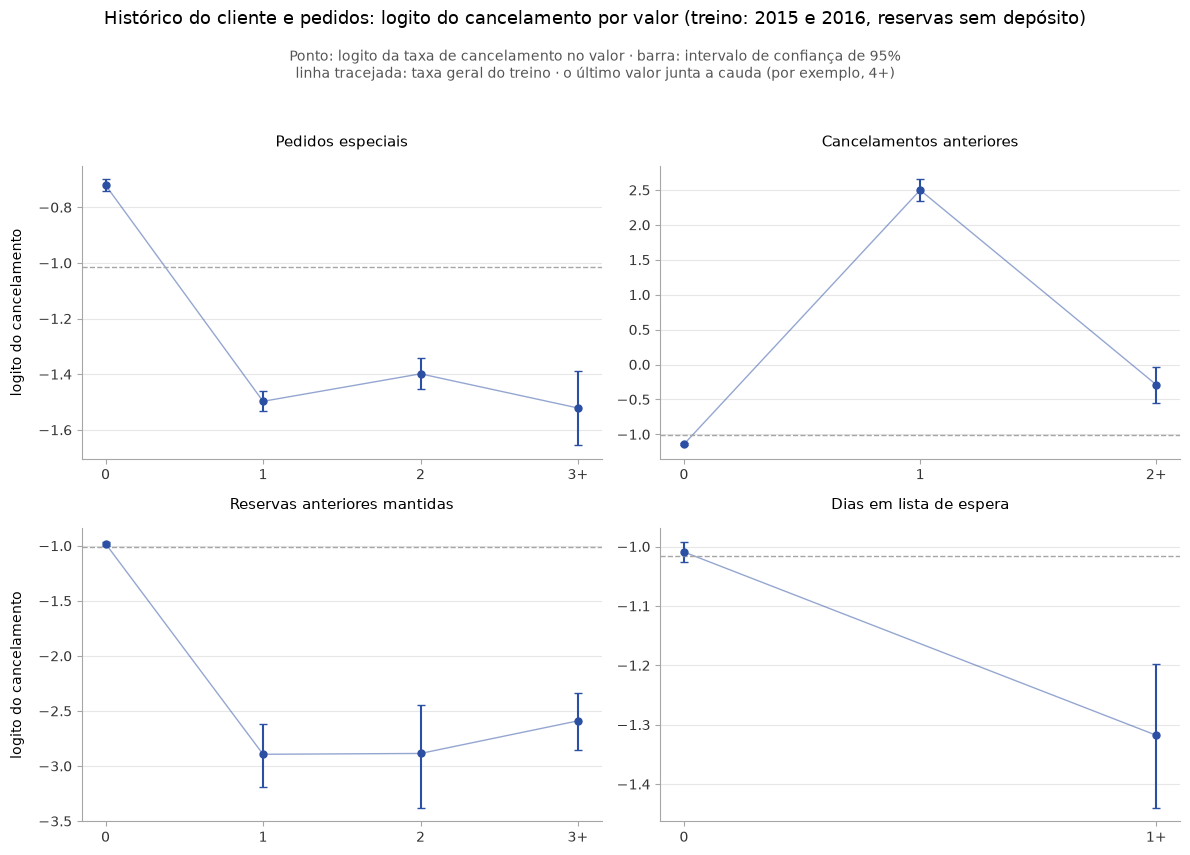

n   taxa  ic_inf  ic_sup
adults                         0        160  0.331   0.263   0.407
                               1      13720  0.196   0.189   0.202
                               2      50507  0.282   0.278   0.286
                               3       3547  0.297   0.282   0.312
                               4+        56  0.411   0.292   0.541
children                       0      62954  0.261   0.257   0.264
                               1       2859  0.290   0.274   0.307
                               2+      2177  0.380   0.360   0.400
babies                         0      67331  0.266   0.263   0.270
                               1+       659  0.206   0.177   0.239
noites                         0        535  0.036   0.023   0.055
                               1      13318  0.196   0.189   0.203
                               2      14477  0.265   0.258   0.272
                               3      14350  0.280   0.273   0.288
                               4      10025  0.307   0.298   0.316
                               5       4657  0.279   0.266   0.292
                               6       2250  0.310   0.291   0.329
                               7       5055  0.291   0.278   0.303
                               8–10    2036  0.318   0.298   0.338
                               11–14   1055  0.259   0.233   0.286
                               15+      232  0.547   0.483   0.610
total_of_special_requests      0      38295  0.327   0.323   0.332
                               1      20433  0.183   0.178   0.188
                               2       7793  0.198   0.189   0.207
                               3+      1469  0.179   0.160   0.199
previous_cancellations         0      65434  0.242   0.239   0.245
                               1       2322  0.924   0.913   0.934
                               2+       234  0.427   0.366   0.491
previous_bookings_not_canceled 0      65819  0.273   0.269   0.276
                               1        942  0.052   0.040   0.068
                               2        349  0.052   0.033   0.080
                               3+       880  0.069   0.054   0.088
days_in_waiting_list           0      66426  0.267   0.264   0.271
                               1+      1564  0.211   0.191   0.232

In [9]:
# contagens: o último nível junta a cauda (por exemplo, 4+ = 4 ou mais adultos)
grupos = {
    'Quem viaja e por quanto tempo': [
        ('adults', [-1, 0, 1, 2, 3, np.inf], ['0', '1', '2', '3', '4+'], 'Adultos'),
        ('children', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Crianças'),
        ('babies', [-1, 0, np.inf], ['0', '1+'], 'Bebês'),
        ('noites', [-1, 0, 1, 2, 3, 4, 5, 6, 7, 10, 14, np.inf],
         ['0', '1', '2', '3', '4', '5', '6', '7', '8–10', '11–14', '15+'], 'Total de noites'),
    ],
    'Histórico do cliente e pedidos': [
        ('total_of_special_requests', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Pedidos especiais'),
        ('previous_cancellations', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Cancelamentos anteriores'),
        ('previous_bookings_not_canceled', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Reservas anteriores mantidas'),
        ('days_in_waiting_list', [-1, 0, np.inf], ['0', '1+'], 'Dias em lista de espera'),
    ],
}

tabelas = {}
for tema, contagens in grupos.items():
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8.5))
    for ax, (coluna, limites, rotulos, titulo) in zip(eixos.flat, contagens):
        tabelas[coluna] = logito_por_faixa(treino, coluna, limites=limites)
        tabelas[coluna]['x'] = range(len(rotulos))   # níveis igualmente espaçados; a cauda fica no último
        tabelas[coluna].index = rotulos
        grafico_logito(tabelas[coluna], titulo=titulo, taxa_geral=taxa_treino, ax=ax)
        ax.set_xticks(range(len(rotulos)), rotulos)
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('logito do cancelamento')
    fig.suptitle(f'{tema}: logito do cancelamento por valor (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 0.955, 'Ponto: logito da taxa de cancelamento no valor · barra: intervalo de confiança de 95%\n'
             'linha tracejada: taxa geral do treino · o último valor junta a cauda (por exemplo, 4+)',
             ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, 0.91))
    plt.show()

pd.concat({c: t[['n', 'taxa', 'ic_inf', 'ic_sup']] for c, t in tabelas.items()}).round(3)


**Leitura.**

- **`adults`: o nível 1 se separa.** Um adulto cancela 19,6%; dois, 28,2%; três, 29,7%, com intervalos que quase se tocam. Os extremos têm poucas reservas e intervalos largos: 0 adulto (160 reservas, 33,1%) e 4 ou mais (56, 41,1%). **Binária: sozinho (1 adulto) × acompanhado** (os demais, incluindo os 160 sem adulto).
- **`children`: escada.** Sem criança, 26,1%; uma, 29,0%; duas ou mais, 38,0%. **Binária, com criança × sem**, ou três níveis se o modelo mostrar que a diferença entre uma e duas compensa.
- **`babies` vai no sentido oposto.** Com bebê, 20,6% (IC de 17,7% a 23,9%), contra 26,6% sem. Juntar com `children` misturaria efeitos contrários. São 659 reservas (1% do treino). **Sai.**
- **`noites`: zero noites é outro comportamento.** 3,6% de cancelamento (535 reservas), contra 19,6% com uma noite; de 2 a 14 noites, a taxa fica entre 25,9% e 31,8%. 15 noites ou mais cancelam 54,7%, mas são só 232. **Entra em faixas** (abaixo).
- **`total_of_special_requests`: o que importa é fazer algum pedido.** Sem pedido, 32,7%; com 1, 2 ou 3 ou mais, entre 17,9% e 19,8%. **Binária: fez pedido × não fez**, se o momento do score permitir.
- **`previous_bookings_not_canceled`: o mesmo desenho.** Nunca veio, 27,3%; já veio uma ou mais vezes, entre 5,2% e 6,9%. **Binária: já veio × nunca veio.**
- **`days_in_waiting_list`:** quem esperou cancela 21,1%, contra 26,7%. São 2,3% das reservas: pouco ganho para uma variável a mais. **Sai.**
- **`previous_cancellations` não segue escada nenhuma:** uma vez, 92,4%; duas ou mais, 42,7%. Investigado abaixo.

In [10]:
# cancelamentos anteriores: quem são as reservas com exatamente 1?
treino_pc = treino.assign(cancelou_antes=treino['previous_cancellations'].clip(upper=2))
display(treino_pc.groupby('cancelou_antes').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_2015=('arrival_date_year', lambda s: (s == 2015).mean()),
    antecedencia_mediana=('lead_time', 'median'),
    pct_com_gemea=('tem_gemea', 'mean'),
    pct_hospede_repetido=('is_repeated_guest', 'mean'),
).rename(index={2: '2 ou mais'}))

# a relação se mantém em 2017?
pd.DataFrame({
    'taxa_treino': treino.groupby(treino['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'taxa_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'n_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2)).size(),
}).rename(index={2: '2 ou mais'}).round(3)

,reservas,taxa,pct_2015,antecedencia_mediana,pct_com_gemea,pct_hospede_repetido
cancelou_antes,,,,,,
0,65434,0.241908,0.250206,49.0,0.251887,0.025904
1,2322,0.924203,0.798450,199.0,0.651163,0.197244
2 ou mais,234,0.427350,0.282051,8.0,0.252137,0.700855


,taxa_treino,taxa_teste,n_teste
previous_cancellations,,,
0,0.242,0.319,36189
1,0.924,0.175,194
2 ou mais,0.427,0.169,83


**Leitura.**

- **As reservas com exatamente um cancelamento anterior não são clientes que costumam cancelar.** 79,8% são de 2015 (contra 25,0% das reservas sem cancelamento anterior), têm antecedência mediana de 199 dias e 65,1% têm gêmea. É o perfil dos blocos de quartos do notebook 01, seção 4.2, concentrados no início da base.
- **Em 2017, a relação se inverte.** No teste, quem tem um cancelamento anterior cancela 17,5%, contra 31,9% de quem não tem. No treino eram 92,4%. Uma variável que muda de sentido entre os períodos ensinaria ao modelo uma regra que não vale no futuro.
- **Explicação provável:** em 2015, a contagem parece registrar os outros quartos do mesmo bloco cancelado, e não o histórico do cliente. Não dá para confirmar sem o sistema do hotel.
- **Proposta: sai.** O histórico do cliente continua representado por "já veio × nunca veio".

In [11]:
# faixas propostas para a antecedência e o total de noites
faixas_lead = pd.cut(treino['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                     labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180'])
faixas_noites = pd.cut(treino['noites'], [-1, 1, 3, 7, np.inf], labels=['até 1', '2–3', '4–7', 'mais de 7'])

display(taxa_por_nivel(treino.assign(faixa_lead=faixas_lead), 'faixa_lead')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(3))
taxa_por_nivel(treino.assign(faixa_noites=faixas_noites), 'faixa_noites')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(3)

,n,pct_base,taxa,ic_inf,ic_sup
faixa_lead,,,,,
até 7,13764,0.202,0.095,0.090,0.100
8–30,12261,0.180,0.248,0.241,0.256
31–90,18721,0.275,0.308,0.301,0.314
91–180,13177,0.194,0.334,0.326,0.342
mais de 180,10067,0.148,0.354,0.345,0.363


,n,pct_base,taxa,ic_inf,ic_sup
faixa_noites,,,,,
até 1,13853,0.204,0.190,0.183,0.197
2–3,28827,0.424,0.273,0.268,0.278
4–7,21987,0.323,0.297,0.291,0.303
mais de 7,3323,0.049,0.315,0.300,0.331


**Leitura.**

- **Antecedência em cinco faixas:** até 7 dias, 9,5%; 8–30, 24,8%; 31–90, 30,8%; 91–180, 33,4%; mais de 180, 35,4%. As faixas acompanham a curva, e os intervalos de faixas vizinhas não se sobrepõem. A primeira junta o mesmo dia (7,6%) e de 2 a 7 dias (11,4%), que ficam próximos. **Proposta: estas faixas, com 31–90 como referência** (a maior, 27,5% do treino).
- **Noites em quatro faixas:** até 1, 19,0%; 2–3, 27,3%; 4–7, 29,7%; mais de 7, 31,5%. Juntar as 535 reservas de zero noites com as de uma noite quase não mexe na faixa (de 19,6% para 19,0%) e evita uma categoria de 0,8% do treino. As duas últimas faixas têm intervalos que se tocam (29,1%–30,3% e 30,0%–33,1%): se o modelo não as separar, juntam em "4 ou mais". **Referência: 2–3** (42,4% do treino).

### 3.2 Categóricas: força e agrupamentos

O V de Cramér ordena as candidatas pela força da associação com o cancelamento (de 0 a 1). Com muitos níveis, o V tende a sair maior só por isso: a comparação vale melhor entre variáveis com poucos níveis.

In [12]:
treino = treino.assign(
    segmento=treino['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}),
    tem_agencia=treino['agent'].notna(),
    tem_empresa=treino['company'].notna(),
)

candidatas = ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
              'is_repeated_guest', 'arrival_date_month', 'tem_agencia', 'tem_empresa', 'agent', 'company']
pd.DataFrame({
    'niveis': [treino[c].nunique() for c in candidatas],
    'V_cramer': [v_cramer(treino, c) for c in candidatas],
}, index=candidatas).sort_values('V_cramer', ascending=False).round(3)

,niveis,V_cramer
company,289,0.404
agent,275,0.283
segmento,6,0.195
distribution_channel,5,0.129
tem_agencia,2,0.113
tem_empresa,2,0.087
arrival_date_month,12,0.081
meal,5,0.072
hotel,2,0.070
customer_type,4,0.048


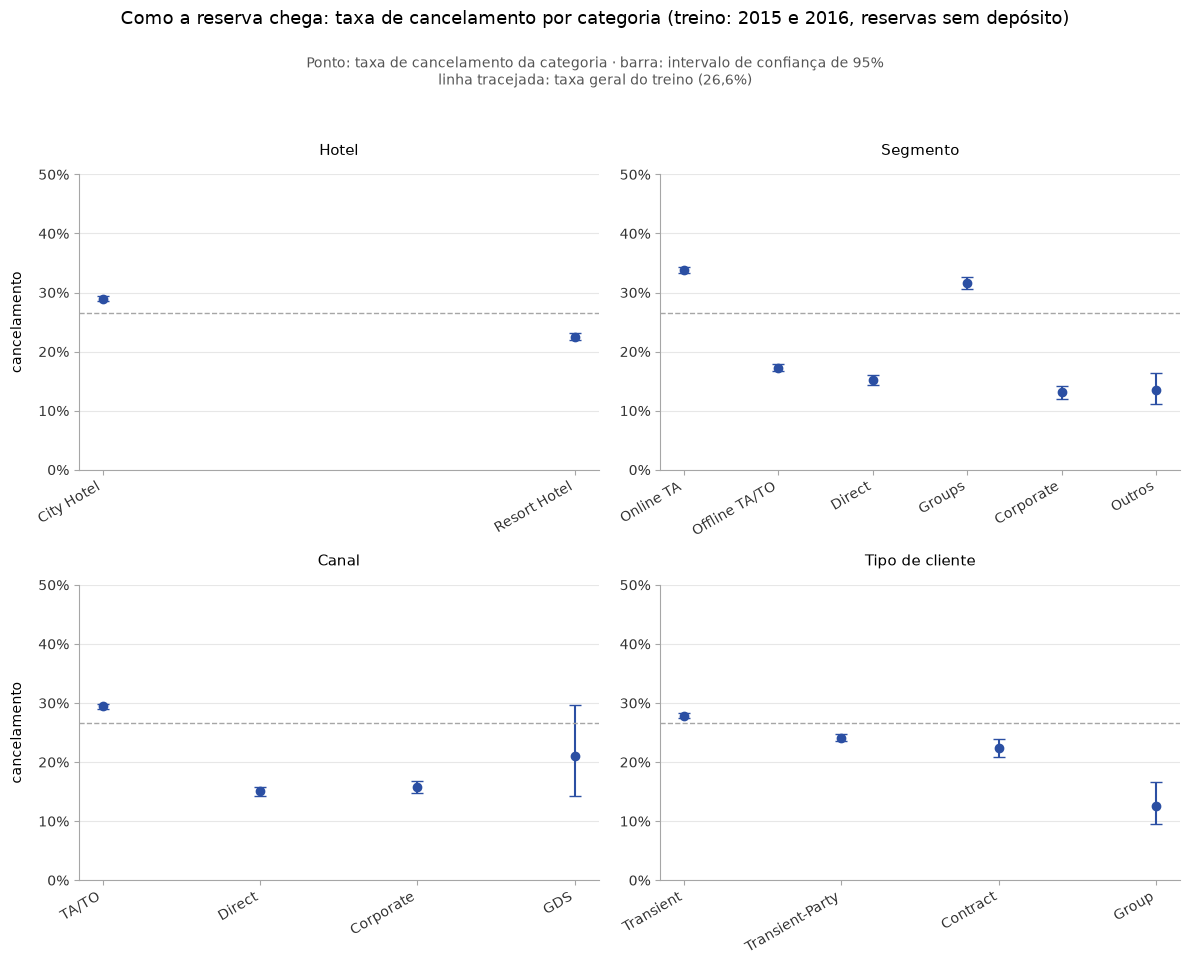

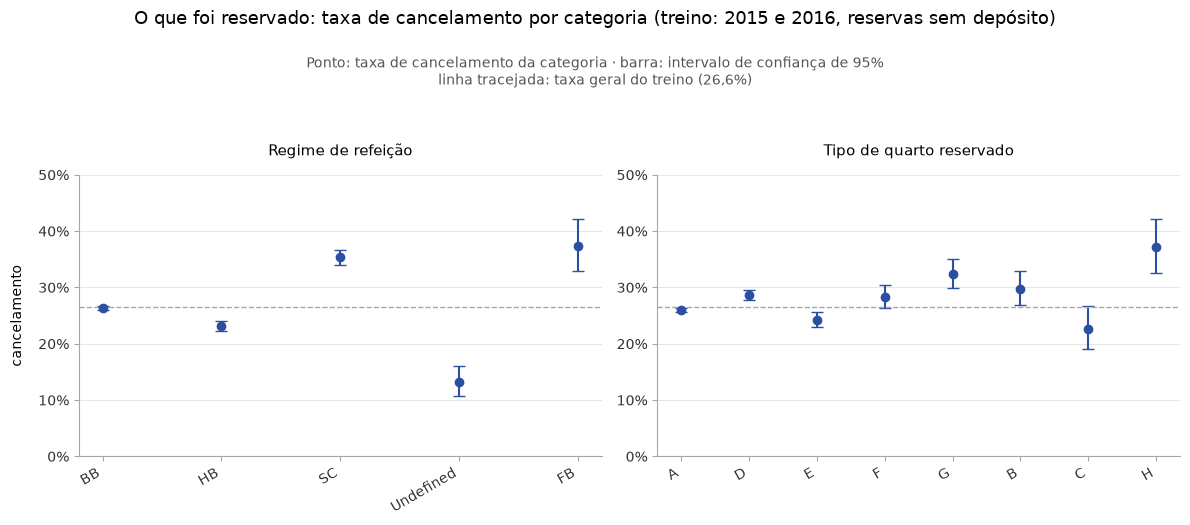

n   taxa  ic_inf  ic_sup
hotel                City Hotel       42651  0.290   0.286   0.294
                     Resort Hotel     25339  0.225   0.220   0.231
segmento             Corporate         3575  0.131   0.120   0.142
                     Direct            7942  0.152   0.144   0.160
                     Groups            7424  0.316   0.305   0.327
                     Offline TA/TO    14666  0.173   0.167   0.179
                     Online TA        33735  0.339   0.334   0.344
                     Outros             648  0.136   0.112   0.164
distribution_channel Corporate         4440  0.157   0.147   0.168
                     Direct            9174  0.150   0.143   0.158
                     GDS                105  0.210   0.143   0.297
                     TA/TO            54270  0.294   0.291   0.298
                     Undefined            1  0.000   0.000   0.793
customer_type        Contract          2866  0.224   0.209   0.239
                     Group              348  0.126   0.096   0.165
                     Transient        46945  0.279   0.275   0.283
                     Transient-Party  17831  0.241   0.235   0.248
meal                 BB               53147  0.263   0.260   0.267
                     FB                 409  0.374   0.329   0.422
                     HB                8382  0.231   0.222   0.240
                     SC                5408  0.353   0.341   0.366
                     Undefined          644  0.132   0.108   0.160
reserved_room_type   A                48026  0.259   0.256   0.263
                     B                  900  0.298   0.269   0.328
                     C                  450  0.227   0.190   0.268
                     D                11427  0.287   0.278   0.295
                     E                 3744  0.243   0.229   0.257
                     F                 1794  0.283   0.263   0.304
                     G                 1256  0.324   0.299   0.350
                     H                  387  0.372   0.325   0.421
                     L                    6  0.333   0.097   0.700
is_repeated_guest    0                65673  0.269   0.265   0.272
                     1                 2317  0.183   0.168   0.200

In [13]:
# níveis com menos de 30 reservas ficam só na tabela (intervalo largo demais para o gráfico)
temas = {
    'Como a reserva chega': [('hotel', 'Hotel'), ('segmento', 'Segmento'),
                             ('distribution_channel', 'Canal'), ('customer_type', 'Tipo de cliente')],
    'O que foi reservado': [('meal', 'Regime de refeição'), ('reserved_room_type', 'Tipo de quarto reservado')],
}
legenda = (f'Ponto: taxa de cancelamento da categoria · barra: intervalo de confiança de 95%\n'
           f'linha tracejada: taxa geral do treino ({taxa_treino:.1%})'.replace('.', ','))

for tema, variaveis in temas.items():
    linhas = (len(variaveis) + 1) // 2
    fig, eixos = plt.subplots(linhas, 2, figsize=(12, 4.4 * linhas + 0.8), squeeze=False)
    for ax, (coluna, titulo) in zip(eixos.flat, variaveis):
        tabela = taxa_por_nivel(treino, coluna).sort_values('n', ascending=False).query('n >= 30')
        grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, titulo=titulo, ax=ax)
        ax.set_ylim(0, 0.5)   # mesma escala em todos, para comparar a força entre variáveis
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('cancelamento')
    topo = 1 - 0.85 / fig.get_figheight()   # espaço fixo para o título e a legenda
    fig.suptitle(f'{tema}: taxa de cancelamento por categoria (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 1 - 0.45 / fig.get_figheight(), legenda, ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, topo))
    plt.show()

pd.concat({c: taxa_por_nivel(treino, c)[['n', 'taxa', 'ic_inf', 'ic_sup']]
           for c in ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
                     'is_repeated_guest']}).round(3)


**Leitura.**

- **O segmento é a categórica mais forte** (V de 0,195). Agência online cancela 33,9% e grupos, 31,6%; operadora tradicional, 17,3%; direto, 15,2%; corporativo, 13,1%. **Entra, com a agência online como referência.**
- **`agent` e `company` têm V alto (0,283 e 0,404), mas com 275 e 289 códigos.** Boa parte disso vem do número de níveis. Investigadas abaixo.
- **O canal repete o segmento com menos detalhe** (V de 0,129). TA/TO (29,4%) mistura a agência online (33,9%) e a operadora tradicional (17,3%). **Sai**; a redundância é conferida na seção 4.
- **Hotel:** urbano 29,0%, resort 22,5% (V de 0,070). **Entra**: é o primeiro corte do negócio.
- **Tipo de cliente:** avulso 27,9%, avulso ligado a outra reserva 24,1%, contrato 22,4% e grupo 12,6% (V de 0,048). Fraco. O nível Group é investigado abaixo.
- **Tipo de quarto:** taxas de 22,7% a 37,2%, sem ordem, e o código não significa nada para o público (V de 0,039). **Sai.**
- **Hóspede que volta:** 18,3% contra 26,9% (V de 0,035). Parecido com "já veio × nunca veio" (seção 3.1); a redundância é conferida na seção 4.

In [14]:
# meal: Undefined e SC são a mesma coisa? Onde cada um aparece
display(pd.crosstab(treino['meal'], treino['hotel'], margins=True, margins_name='total'))
taxa_por_nivel(treino, ['hotel', 'meal'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

hotel,City Hotel,Resort Hotel,total
meal,,,
BB,33626,19521,53147
FB,41,368,409
HB,3616,4766,8382
SC,5368,40,5408
Undefined,0,644,644
total,42651,25339,67990


n   taxa  ic_inf  ic_sup
hotel        meal                                   
City Hotel   BB         33626  0.286   0.281   0.291
             FB            41  0.854   0.716   0.931
             HB          3616  0.224   0.210   0.238
             SC          5368  0.356   0.343   0.369
Resort Hotel BB         19521  0.225   0.219   0.230
             FB           368  0.321   0.275   0.370
             HB          4766  0.236   0.224   0.249
             SC            40  0.025   0.004   0.129
             Undefined    644  0.132   0.108   0.160

**Leitura.**

- **Cada hotel registra "sem refeição" de um jeito.** Undefined só aparece no resort (644 reservas, nenhuma no urbano); SC aparece quase só no urbano (5.368, contra 40 no resort).
- **E os dois vão em sentidos opostos.** No urbano, SC cancela 35,6%, contra 28,6% do café da manhã (BB). No resort, Undefined cancela 13,2%, contra 22,5% do BB. Juntar SC e Undefined em "sem refeição" mistura um efeito para cima com um para baixo.
- **Pensão completa (FB):** 85,4% no urbano, mas são só 41 reservas; 32,1% no resort (368). Meia pensão (HB) fica perto de 23% nos dois hotéis.
- **Proposta: `meal` vai para teste com quatro níveis**: BB (referência), com pensão (HB e FB), SC e Undefined. Undefined fica separado mesmo sendo pequeno (0,9% do treino), porque não se parece com nenhum outro nível. A variável é fraca (V de 0,072): se não melhorar o modelo, sai.

In [15]:
# customer_type = Group (348 reservas): de que segmentos vêm, e com quem se parece?
pd.crosstab(treino['customer_type'], treino['segmento'], normalize='index').round(2)

segmento,Corporate,Direct,Groups,Offline TA/TO,Online TA,Outros
customer_type,,,,,,
Contract,0.01,0.00,0.06,0.41,0.52,0.00
Group,0.04,0.23,0.01,0.38,0.33,0.01
Transient,0.05,0.15,0.01,0.14,0.63,0.01
Transient-Party,0.07,0.04,0.38,0.37,0.13,0.00


**Leitura.**

- **Group (348 reservas, 12,6% de cancelamento) não se parece com nenhum outro tipo de cliente.** O mais próximo é contrato (22,4%). Vem de operadoras (38%), agência online (33%) e reservas diretas (23%): não é o mesmo que o segmento Groups.
- **O avulso ligado a outra reserva (Transient-Party) é 38% do segmento Groups**: o tipo de cliente repete parte do segmento.
- **Sem proposta por ora: a seção 4 decide.** Group tem poucas reservas (348, 0,5% do treino) e não se parece com nenhum outro nível. As possibilidades:
  - **juntar com contrato:** a taxa mais próxima (22,4%), mas ainda 10 pontos acima, e os intervalos não se tocam;
  - **juntar com o avulso ligado a outra reserva:** o conceito mais próximo (reservas ligadas a outras), mas com taxa mais longe (24,1%);
  - **deixar separado**, como Undefined em `meal`: coerente com o critério de lá, mas o efeito sai instável com 348 reservas;
  - **tirar `customer_type` do modelo:** a variável é fraca (V de 0,048) e repete parte do segmento. Se a seção 4 mostrar que ela não acrescenta nada ao segmento, a questão do Group desaparece.

In [16]:
# mês de chegada: o padrão se repete nos dois anos do treino?
por_mes_ano = treino.pivot_table(index='arrival_date_month', columns='arrival_date_year',
                                 values='is_canceled', aggfunc=['mean', 'size']).reindex(meses)
display(por_mes_ano.round(3))

temporada = treino['arrival_date_month'].map({'July': 'jul–ago', 'August': 'jul–ago',
                                              'April': 'abr–jun', 'May': 'abr–jun', 'June': 'abr–jun'}).fillna('set–mar')
taxa_por_nivel(treino.assign(temporada=temporada), ['temporada', 'arrival_date_year'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(3)

mean           size        
arrival_date_year    2015   2016    2015    2016
arrival_date_month                              
January               NaN  0.175     NaN  2050.0
February              NaN  0.247     NaN  3382.0
March                 NaN  0.228     NaN  4229.0
April                 NaN  0.260     NaN  4481.0
May                   NaN  0.258     NaN  4745.0
June                  NaN  0.260     NaN  4316.0
July                0.404  0.285  2544.0  4282.0
August              0.307  0.327  3299.0  4792.0
September           0.228  0.274  3905.0  4636.0
October             0.170  0.322  3868.0  5411.0
November            0.177  0.255  2248.0  3755.0
December            0.201  0.323  2428.0  3619.0

n   taxa  ic_inf  ic_sup
temporada arrival_date_year                              
abr–jun   2016               13542  0.259   0.252   0.267
jul–ago   2015                5843  0.350   0.338   0.362
          2016                9074  0.307   0.298   0.317
set–mar   2015               12449  0.196   0.189   0.203
          2016               27082  0.269   0.264   0.275

**Leitura.**

- **O padrão por mês não se repete nos dois anos.** Julho cancelou 40,4% em 2015 e 28,5% em 2016; outubro, 17,0% e 32,2%; dezembro, 20,1% e 32,3%. Com 12 meses como categorias, o modelo aprenderia oscilações de um ano só.
- **Só julho e agosto ficam acima nos dois anos:** 35,0% em 2015 e 30,7% em 2016. Os outros meses mudam de nível de um ano para o outro.
- **Abril a junho não se separa de setembro a março.** Em 2016, o único ano com os dois períodos, cancelam 25,9% e 26,9%, com intervalos que se tocam. As três temporadas do dicionário viram, na prática, duas.
- **Proposta: alta temporada (julho e agosto) × resto do ano.** A diferença de 2015 para 2016 em setembro a março (19,6% para 26,9%) é a mesma tendência de alta vista no notebook 01, seção 3, e não um efeito da época do ano.

In [17]:
# agência e empresa: o vazio diz algo além do segmento?
display(taxa_por_nivel(treino, ['segmento', 'tem_agencia'])[['n', 'taxa']].round(3))
display(taxa_por_nivel(treino, ['segmento', 'tem_empresa'])[['n', 'taxa']].round(3))

# as maiores agências: o código separa reservas de risco diferente?
maiores = treino['agent'].value_counts().head(8).index
print('Agências no treino:', treino['agent'].nunique(),
      f"| as 8 maiores somam {treino['agent'].isin(maiores).mean():.1%} das reservas")
(taxa_por_nivel(treino[treino['agent'].isin(maiores)], ['agent', 'segmento'])[['n', 'taxa']]
     .query('n >= 100').round(3))

n   taxa
segmento      tem_agencia              
Corporate     False         3023  0.125
              True           552  0.165
Direct        False         4201  0.126
              True          3741  0.181
Groups        False         1537  0.230
              True          5887  0.338
Offline TA/TO False          148  0.257
              True         14518  0.172
Online TA     False          227  0.070
              True         33508  0.341
Outros        False          566  0.133
              True            82  0.159

n   taxa
segmento      tem_empresa              
Corporate     False          649  0.154
              True          2926  0.126
Direct        False         7810  0.153
              True           132  0.106
Groups        False         6799  0.340
              True           625  0.048
Offline TA/TO False        14638  0.173
              True            28  0.071
Online TA     False        33666  0.339
              True            69  0.043
Outros        False          315  0.121
              True           333  0.150

Agências no treino: 275 | as 8 maiores somam 58.2% das reservas


,,n,taxa
agent,segmento,,
1.0,Groups,3074,0.390
6.0,Offline TA/TO,1984,0.138
7.0,Online TA,2123,0.138
9.0,Online TA,18656,0.386
14.0,Direct,1967,0.195
28.0,Offline TA/TO,1124,0.045
240.0,Online TA,8922,0.358
250.0,Direct,1687,0.164


**Leitura.**

- **`tem_agencia` repete o segmento.** Na agência online e na operadora, quase todas as reservas têm agência; as sem agência são poucas (227 e 148). Onde há volume nos dois lados (direto, corporativo e grupos), ter agência soma de 4 a 11 pontos, mas o segmento já separa a maior parte. **Sai.**
- **`tem_empresa` separa dentro do segmento.** Nos grupos, a reserva paga por empresa cancela 4,8% (625 reservas), contra 34,0% sem empresa. No corporativo, a diferença é pequena (12,6% contra 15,4%). São 4.113 reservas com empresa (6,0% do treino). **Proposta: testar "paga por empresa" como binária.** A empresa é conhecida na reserva, e a leitura para o negócio é direta.
- **O código da agência separa reservas do mesmo segmento.** Na agência online, a agência 9 cancela 38,6% e a 7, 13,8%; na operadora, a 6 cancela 13,8% e a 28, 4,5%. Mas são 275 códigos anônimos, e as 8 maiores somam 58,2% das reservas. **Sai do modelo:** dummies por código não se explicam para a diretoria. **Próximo passo para o negócio:** com o nome real das agências, a taxa por agência vira uma lista de parceiros a acompanhar.

### 3.3 Treino × teste: a relação se mantém em 2017?

A seção 2.3 mostrou que 2017 tem diárias mais altas e mais reservas da agência online e com antecedência longa. Duas perguntas ficaram abertas:

1. a diária se relaciona com o cancelamento do mesmo jeito nos dois períodos?
2. quanto da alta de 2017 (de 26,6% para 31,8%) vem da mudança no perfil das reservas, e quanto de um cancelamento maior dentro de cada perfil?

treino                      teste                     
                    n   taxa ic_inf ic_sup     n   taxa ic_inf ic_sup
decil_adr                                                            
(-inf, 47.0]     6822  0.157  0.149  0.166  2404  0.181  0.166  0.197
(47.0, 62.0]     7096  0.262  0.252  0.273  2113  0.236  0.219  0.255
(62.0, 72.0]     6680  0.245  0.235  0.255  2102  0.186  0.169  0.203
(72.0, 80.75]    6940  0.279  0.268  0.289  3057  0.276  0.261  0.292
(80.75, 90.0]    6776  0.227  0.217  0.237  3004  0.324  0.307  0.341
(90.0, 100.0]    6724  0.272  0.262  0.283  3356  0.291  0.276  0.307
(100.0, 113.0]   6557  0.288  0.277  0.299  3616  0.319  0.304  0.334
(113.0, 129.0]   6807  0.305  0.294  0.316  4507  0.338  0.324  0.352
(129.0, 156.6]   6811  0.311  0.300  0.322  5283  0.383  0.370  0.396
(156.6, inf]     6777  0.312  0.301  0.323  7024  0.395  0.384  0.407

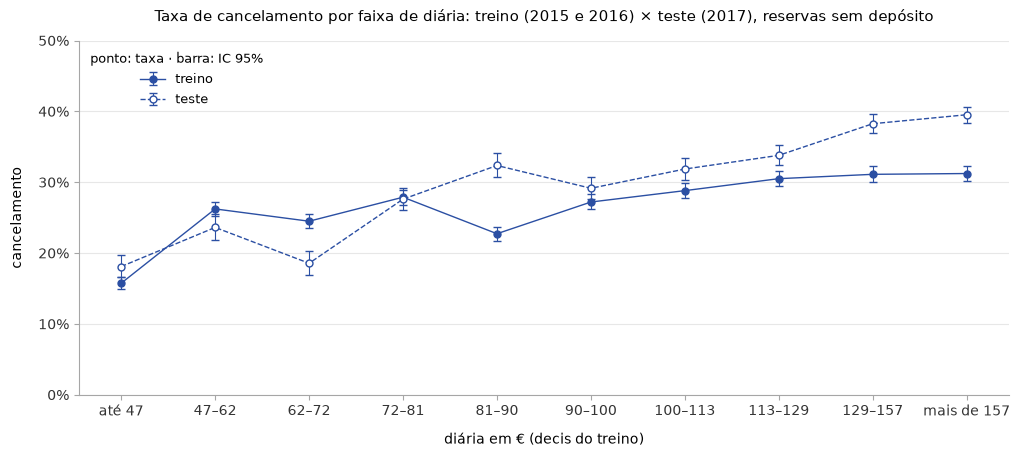

,treino,teste
hotel,,
City Hotel,96.0,114.4
Resort Hotel,72.0,88.0


In [18]:
teste = teste.assign(
    segmento=teste['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}))

from matplotlib.ticker import PercentFormatter

# diária: decis do treino aplicados aos dois períodos (o corte é o mesmo, o preço é que muda)
cortes_adr = treino['adr'].quantile(np.linspace(0, 1, 11)).to_numpy().copy()
cortes_adr[0], cortes_adr[-1] = -np.inf, np.inf
por_decil = pd.concat({
    periodo: taxa_por_nivel(dados.assign(decil_adr=pd.cut(dados['adr'], cortes_adr)), 'decil_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']]
    for periodo, dados in [('treino', treino), ('teste', teste)]
}, axis=1)
display(por_decil.round(3))

fig, ax = plt.subplots(figsize=(12, 4.6))
posicoes = np.arange(len(por_decil))
for periodo, estilo in [('treino', dict(marker='o', linestyle='-')), ('teste', dict(marker='o', linestyle='--', markerfacecolor='white'))]:
    taxa = por_decil[(periodo, 'taxa')]
    erro = [taxa - por_decil[(periodo, 'ic_inf')], por_decil[(periodo, 'ic_sup')] - taxa]
    ax.errorbar(posicoes, taxa, yerr=erro, capsize=3, color=CORES['principal'], label=periodo,
                linewidth=1, elinewidth=0.8, markersize=5, **estilo)
rotulos = [f'{i.left:.0f}–{i.right:.0f}' for i in por_decil.index]
rotulos[0], rotulos[-1] = f'até {por_decil.index[0].right:.0f}', f'mais de {por_decil.index[-1].left:.0f}'
ax.set_xticks(posicoes, rotulos)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('diária em € (decis do treino)')
ax.set_ylabel('cancelamento')
ax.set_title('Taxa de cancelamento por faixa de diária: treino (2015 e 2016) × teste (2017), reservas sem depósito')
ax.legend(frameon=False, title='ponto: taxa · barra: IC 95%', title_fontsize=9, fontsize=9)
plt.show()

# preço: a mediana da diária sobe nos dois hotéis
pd.concat({'treino': treino.groupby('hotel')['adr'].median(), 'teste': teste.groupby('hotel')['adr'].median()}, axis=1)

**Leitura.**

- **A relação da diária com o cancelamento muda em 2017.** Nas duas faixas mais caras do treino (acima de 129), o teste cancela 38,3% e 39,5%, contra 31,1% e 31,2% no treino. No meio da escala, as faixas sobem e descem sem padrão: de 62 a 72, 18,6% no teste contra 24,5%; de 81 a 90, 32,4% contra 22,7%.
- **Parte disso é preço.** A diária mediana sobe de 96 para 114,4 no hotel urbano e de 72 para 88 no resort. Com as faixas fixas do treino, uma mesma faixa em euros junta reservas diferentes em cada ano: a faixa acima de 157 tem 6.777 reservas no treino e 7.024 no teste, que tem pouco mais da metade das reservas.
- **Consequência:** a diária em euros não serve como está. A seção 4 confere se ela acrescenta algo depois de controlar segmento e antecedência, que também mudam em 2017. Se não acrescentar, sai.

In [19]:
# perfil × comportamento: a taxa do treino em cada grupo de reservas, com o perfil de 2017
grupos_perfil = ['hotel', 'segmento', 'faixa_lead', 'temporada']
def com_perfil(dados):
    return dados.assign(
        faixa_lead=pd.cut(dados['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                          labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180']),
        temporada=np.where(dados['arrival_date_month'].isin(['July', 'August']), 'jul–ago', 'resto'))

taxa_grupo_treino = com_perfil(treino).groupby(grupos_perfil, observed=True)['is_canceled'].mean()
perfil_teste = com_perfil(teste).groupby(grupos_perfil, observed=True).size()
taxa_aplicada = taxa_grupo_treino.reindex(perfil_teste.index)
cobertos = taxa_aplicada.notna()
esperada_2017 = (perfil_teste[cobertos] * taxa_aplicada[cobertos]).sum() / perfil_teste[cobertos].sum()

alta = teste['is_canceled'].mean() - treino['is_canceled'].mean()
print(f"Parte da alta explicada só pelo perfil: {(esperada_2017 - treino['is_canceled'].mean()) / alta:.0%}")
print(f"Reservas de 2017 em grupos que existem no treino: {perfil_teste[cobertos].sum() / perfil_teste.sum():.1%}")
pd.Series({
    'treino (taxa real)': treino['is_canceled'].mean(),
    '2017 com as taxas do treino (só o perfil muda)': esperada_2017,
    '2017 (taxa real)': teste['is_canceled'].mean(),
}).to_frame('cancelamento').round(4)

Parte da alta explicada só pelo perfil: 69%
Reservas de 2017 em grupos que existem no treino: 100.0%


,cancelamento
treino (taxa real),0.2658
2017 com as taxas do treino (só o perfil muda),0.3018
2017 (taxa real),0.3178


**Leitura.**

- **Cerca de 70% da alta de 2017 vem da mudança no perfil das reservas.** Aplicando as taxas do treino de cada grupo (hotel × segmento × faixa de antecedência × temporada) ao perfil de 2017, a taxa esperada seria 30,2%. A real foi 31,8%, e o treino tinha 26,6%: o perfil explica 69% dos 5,2 pontos de alta. Todas as reservas de 2017 caem em grupos que existem no treino.
- **O resto, cerca de 1,6 ponto, é cancelamento maior dentro do mesmo perfil.** É a parte que o modelo não capta e que aparece na calibração.

In [20]:
# onde a taxa mudou dentro do perfil: segmento e antecedência, treino × teste
def taxa_e_peso(variavel, dados_treino, dados_teste):
    return pd.DataFrame({
        'pct_treino': dados_treino[variavel].value_counts(normalize=True),
        'pct_teste': dados_teste[variavel].value_counts(normalize=True),
        'taxa_treino': dados_treino.groupby(variavel, observed=True)['is_canceled'].mean(),
        'taxa_teste': dados_teste.groupby(variavel, observed=True)['is_canceled'].mean(),
    })

display(taxa_e_peso('segmento', treino, teste).sort_values('pct_teste', ascending=False).round(3))
display(taxa_e_peso('faixa_lead', com_perfil(treino), com_perfil(teste)).round(3))

online_treino = com_perfil(treino).query("segmento == 'Online TA'")
online_teste = com_perfil(teste).query("segmento == 'Online TA'")
print('Só a agência online:')
taxa_e_peso('faixa_lead', online_treino, online_teste).round(3)

,pct_treino,pct_teste,taxa_treino,taxa_teste
segmento,,,,
Online TA,0.496,0.620,0.339,0.409
Direct,0.117,0.127,0.152,0.153
Offline TA/TO,0.216,0.124,0.173,0.169
Groups,0.109,0.084,0.316,0.204
Corporate,0.053,0.038,0.131,0.153
Outros,0.010,0.009,0.136,0.168


,pct_treino,pct_teste,taxa_treino,taxa_teste
faixa_lead,,,,
até 7,0.202,0.157,0.095,0.082
8–30,0.180,0.169,0.248,0.285
31–90,0.275,0.230,0.308,0.354
91–180,0.194,0.249,0.334,0.371
mais de 180,0.148,0.195,0.354,0.426


Só a agência online:


,pct_treino,pct_teste,taxa_treino,taxa_teste
faixa_lead,,,,
até 7,0.172,0.109,0.095,0.085
8–30,0.205,0.178,0.310,0.338
31–90,0.315,0.257,0.383,0.422
91–180,0.214,0.266,0.427,0.467
mais de 180,0.094,0.190,0.499,0.561


**Leitura.**

- **A agência online explica a maior parte da mudança.** Passa de 49,6% para 62,0% das reservas, e a taxa dela sobe de 33,9% para 40,9%. Nos grupos, a taxa cai de 31,6% para 20,4%; nos outros segmentos, quase não muda.
- **Dentro da agência online, a antecedência também se alonga.** As reservas com mais de 180 dias passam de 9,4% para 19,0%. E a taxa sobe em todas as faixas a partir de 8 dias, de 2,8 a 6,2 pontos: com mais de 180 dias, de 49,9% para 56,1%.
- **No total, a taxa sobe em todas as faixas de antecedência a partir de 8 dias** (de 3,7 a 7,2 pontos) e cai um pouco nas reservas de até 7 dias (de 9,5% para 8,2%).
- **O que isso muda:**
  - com segmento e antecedência no modelo, a maior parte da alta de 2017 é captada. A previsão para 2017 deve sair baixa em cerca de 1,6 ponto, e não em 5;
  - a ordem das reservas quase se mantém: na antecedência e na agência online, quem cancelava mais no treino continua cancelando mais em 2017. A exceção são os grupos, que caem de 31,6% para 20,4% e passam a ficar abaixo da média;
  - a interação agência online × antecedência fica para a seção 4: dentro da agência online, a antecedência separa muito mais (de 8,5% a 56,1% no teste) do que na base toda.

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa com os notebooks do grupo está em `comparacao_decisoes.md`. Os pontos de escopo e limpeza estão no fim do `01_exploratoria.ipynb`.*

| # | Decisão | Proposta deste notebook | Evidência | Notebooks do grupo |
| --- | --- | --- | --- | --- |
| 1 | **Faixas de antecedência** | Até 7, 8–30, 31–90, 91–180 e mais de 180 dias, com 31–90 como referência | 3.1 | Mesmas faixas |
| 2 | **Faixas de noites** | Até 1 (com as zero noites), 2–3, 4–7 e mais de 7, com 2–3 como referência; juntar 4–7 e mais de 7 se o modelo não as separar | 3.1 | Dicionário: mesmas faixas. Notebook 03: zero noites numa faixa própria |
| 3 | **`previous_cancellations`** | Sai: 1 cancelamento anterior cancela 92,4% no treino e 17,5% no teste | 3.1 | Testar: já cancelou × nunca cancelou |
| 4 | **Crianças e bebês** | "Com criança" só com `children`; `babies` sai (com bebê cancela 20,6%, contra 26,6% sem) | 3.1 | `com_crianca` soma crianças e bebês |
| 5 | **`meal`** | Testar com quatro níveis: BB (referência), com pensão (HB e FB), SC e Undefined | 3.2 | Sem refeição (SC e Undefined) × com refeição |
| 6 | **Temporadas** | Duas: julho e agosto × resto do ano | 3.2 | Três: jul–ago, abr–jun e set–mar |
| 7 | **`customer_type`** | A decidir na seção 4: entra ou sai e, se entrar, o destino do nível Group | 3.2 | Entra |
| 8 | **`company`** | Testar a binária "paga por empresa" | 3.2 | Sai |
| 9 | **`adr`** | Em euros, não serve como está; a seção 4 decide se entra | 3.3 | Entra como número |
| 10 | **Leitura da alta de 2017** | 69% vem da mudança no perfil das reservas | 3.3 | Notebook 03: "sobretudo comportamento". Conferir se a diferença vem dos grupos usados em cada decomposição |